In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [ ]:
df=pd.read_csv("winequality.csv")
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [ ]:
df.isnull().sum()

,0
type,0
fixed acidity,10
volatile acidity,8
citric acid,3
residual sugar,2
chlorides,2
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,9


In [ ]:
df1=df.fillna(method="ffill")
df1.isnull().sum()

/tmp/ipykernel_3838/3369953911.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1=df.fillna(method="ffill")


,0
type,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0


In [ ]:
y=df1['type']
x=df1.drop(['type'],axis=1)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

In [ ]:
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)

In [ ]:
print(y.unique)

<bound method Series.unique of 0       white
1       white
2       white
3       white
4       white
        ...  
6492      red
6493      red
6494      red
6495      red
6496      red
Name: type, Length: 6497, dtype: object>


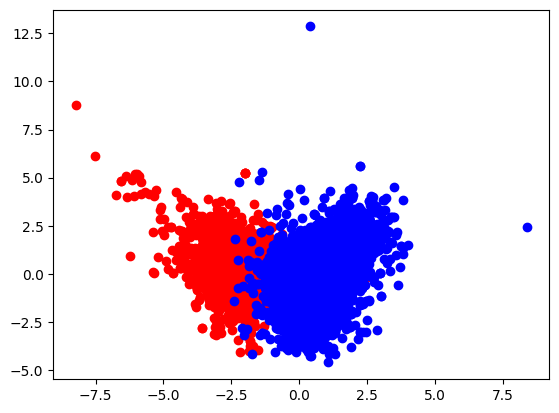

In [ ]:
plt.scatter(x_pca[y == 'red',0],x_pca[y == 'red',1],label="red wine",c="red")
plt.scatter(x_pca[y == 'white',0],x_pca[y == 'white',1],label="white wine",c="blue")

In [ ]:
from sklearn.linear_model import LogisticRegression


x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)


x_train_pca = pca.transform(x_train_scaled)
X_test_scaled = pca.transform(x_test_scaled)


model = LogisticRegression(random_state=0)
model.fit(x_train_pca, y_train)


y_pred = model.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import accuracy_score

y_test_numeric = y_test.apply(lambda x: 1 if x == 'white' else 0)
y_pred_numeric = pd.Series(y_pred).apply(lambda x: 1 if x == 'white' else 0)


accuracy = accuracy_score(y_test_numeric, y_pred_numeric)

print("Accuracy :", accuracy)

Accuracy : 0.9792307692307692


In [ ]:
print("Accuracy : {:.2f}%".format(accuracy * 100))

Accuracy : 97.92%


In [ ]:
import seaborn as sns

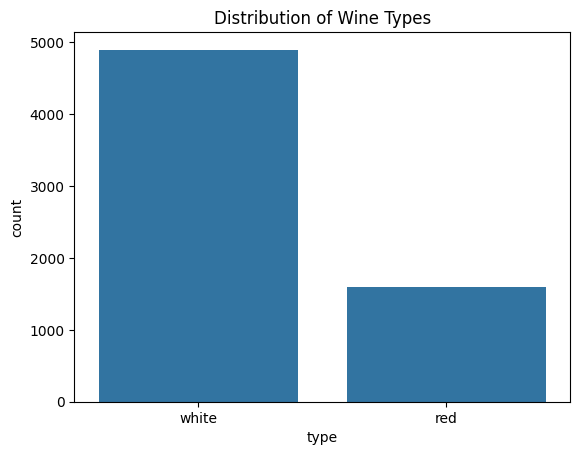

In [ ]:
sns.countplot(x="type",data=df)
plt.title("Distribution of Wine Types")
plt.show()